<a href="https://colab.research.google.com/github/DonovanHaines/CHEM5385.02/blob/main/SimpleHandCalcNeuralNetwork.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

#  Testing a very simple neural network with two imputs, three hidden-layer
#  neurons, and one outuput neuron. Each neuron has a bias to be added.

#   Input Layer          Hidden Layer            Output Layer
#    (Features)           (3 Neurons)             (1 Predictor)
#                         (Only two shown)
#      [ x₁ ] ----------> ( Neuron 1 ) -------\
#               \      /  with bias b₁_₁       \
#                \    /                         \
#                 \  /                           \
#                  \/                             ----> ( Neuron Output ) ---> Prediction
#                  /\                             ____/  with bias b₂_₁
#                 /  \                           /
#                /    \                         /
#               /      \                       /
#      [ x₂ ] ----------> ( Neuron 2 ) -------/
#                         with bias b₁_₂
import numpy as np

# ----------------------------------------------------
# 1. SETUP DATA AND HYPERPARAMETERS
# ----------------------------------------------------

# Input dataset: 4 sample data points (rows) with 2 features each (columns)
# Example: [Study hours, Attendance rate]
X = np.array([
    [0.5, 0.8],
    [0.1, 0.2],
    [0.9, 0.9],
    [0.3, 0.4]
])

# True expected targets for our data points (e.g., 1 = Pass, 0 = Fail)
# We reshape it to a column vector (4 rows, 1 column) to match network outputs
Y_true = np.array([[1.0], [0.0], [1.0], [0.0]])

# Hyperparameters control how our network architecture learns
learning_rate = 0.1
epochs = 1000  # Number of times the network reviews the entire dataset

# ----------------------------------------------------
# 2. INITIALIZE NETWORK WEIGHTS AND BIASES
# ----------------------------------------------------
# Random seeds keep results identical every time you run the script
np.random.seed(42)

# LAYER 1: Hidden Layer (2 inputs -> 3 neurons)
# Weights are matrices: rows = input connections, columns = target neurons
W1 = np.random.randn(2, 3)
# Biases are vectors: 1 bias slot for each of our 3 hidden neurons
b1 = np.zeros((1, 3))

# LAYER 2: Output Layer (3 hidden neurons -> 1 output neuron)
W2 = np.random.randn(3, 1)
# 1 bias slot for our single final output neuron
b2 = np.zeros((1, 1))

print("--- Starting Training ---")

# ----------------------------------------------------
# 3. THE TRAINING LOOP (Optimization via Gradient Descent)
# ----------------------------------------------------
for epoch in range(epochs):

    # --- STEP A: FORWARD PASS (Making Predictions) ---

    # Calculate Hidden Layer activation
    # Multiplying inputs by weights, then adding the layer 1 biases
    hidden_sum = np.dot(X, W1) + b1
    # Sigmoid Activation squashes numbers between 0 and 1, introducing non-linearity
    hidden_activation = 1 / (1 + np.exp(-hidden_sum))

    # Calculate Output Layer activation
    # Multiplying hidden layer output by weights, then adding the layer 2 bias
    output_sum = np.dot(hidden_activation, W2) + b2
    # Final prediction squash
    Y_pred = 1 / (1 + np.exp(-output_sum))


    # --- STEP B: BACKPROPAGATION (Calculating Error Gradients) ---

    # 1. Total network error (Mean Squared Error Loss)
    loss = np.mean((Y_pred - Y_true) ** 2)

    # 2. Find error at Output Layer
    # Derivative of loss combined with derivative of sigmoid activation
    output_error = Y_pred - Y_true
    output_delta = output_error * (Y_pred * (1 - Y_pred))

    # 3. Find error at Hidden Layer (Distribute output error backward)
    hidden_error = np.dot(output_delta, W2.T)
    hidden_delta = hidden_error * (hidden_activation * (1 - hidden_activation))


    # --- STEP C: GRADIENT DESCENT (Updating Weights & Biases) ---

    # Update layer 2 parameters
    # Dot product averages gradients across all training samples
    W2 -= learning_rate * np.dot(hidden_activation.T, output_delta)
    # Biases simply sum the raw error deltas directly across the samples
    b2 -= learning_rate * np.sum(output_delta, axis=0, keepdims=True)

    # Update layer 1 parameters
    W1 -= learning_rate * np.dot(X.T, hidden_delta)
    b1 -= learning_rate * np.sum(hidden_delta, axis=0, keepdims=True)

    # Every 200 iterations, print out our current loss to track progress
    if epoch % 200 == 0:
        print(f"Epoch {epoch:4d} | Average Error (Loss): {loss:.5f}")
        print("\nCurrent Network Parameters:")
        print(f"Layer 1 Biases (Learned values for 3 hidden nodes): {b1.round(4)}")
        print(f"Layer 2 Bias (Learned value for final output node): {b2.round(4)}")

        print("\nCurrent Predictions vs Truth:")
        for i in range(len(X)):
            print(f"Input: {X[i]} -> Predicted: {Y_pred[i][0]:.4f} (Target: {Y_true[i][0]})")

        print("\n--- End of Epoch Report ---")

# ----------------------------------------------------
# 4. FINAL VERIFICATION
# ----------------------------------------------------
print("\nFinal Network Parameters:")
print(f"Layer 1 Biases (Learned values for 3 hidden nodes): {b1.round(4)}")
print(f"Layer 2 Bias (Learned value for final output node): {b2.round(4)}")

print("\nFinal Predictions vs Truth:")
for i in range(len(X)):
    print(f"Input: {X[i]} -> Predicted: {Y_pred[i][0]:.4f} (Target: {Y_true[i][0]})")


--- Starting Training ---
Epoch    0 | Average Error (Loss): 0.30496

Current Network Parameters:
Layer 1 Biases (Learned values for 3 hidden nodes): [[-0.0088 -0.0041  0.0025]]
Layer 2 Bias (Learned value for final output node): [[-0.0215]]

Current Predictions vs Truth:
Input: [0.5 0.8] -> Predicted: 0.7969 (Target: 1.0)
Input: [0.1 0.2] -> Predicted: 0.7433 (Target: 0.0)
Input: [0.9 0.9] -> Predicted: 0.8023 (Target: 1.0)
Input: [0.3 0.4] -> Predicted: 0.7661 (Target: 0.0)

--- End of Epoch Report ---
Epoch  200 | Average Error (Loss): 0.17418

Current Network Parameters:
Layer 1 Biases (Learned values for 3 hidden nodes): [[-0.8404 -0.1235  0.1575]]
Layer 2 Bias (Learned value for final output node): [[-0.8997]]

Current Predictions vs Truth:
Input: [0.5 0.8] -> Predicted: 0.5782 (Target: 1.0)
Input: [0.1 0.2] -> Predicted: 0.3955 (Target: 0.0)
Input: [0.9 0.9] -> Predicted: 0.6172 (Target: 1.0)
Input: [0.3 0.4] -> Predicted: 0.4647 (Target: 0.0)

--- End of Epoch Report ---
Epoch 

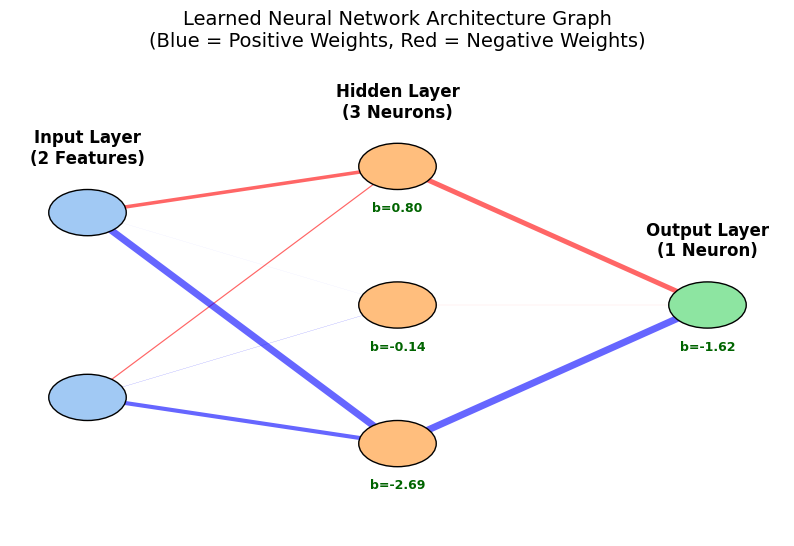

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def draw_neural_network(W1, b1, W2, b2):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.axis('off')

    # Coordinates of layers
    # Input layer (2 nodes)
    layer_0 = [(1, 2), (1, 4)]
    # Hidden layer (3 nodes)
    layer_1 = [(3, 1.5), (3, 3), (3, 4.5)]
    # Output layer (1 node)
    layer_2 = [(5, 3)]

    # Draw connections Input -> Hidden
    for i, p0 in enumerate(layer_0):
        for j, p1 in enumerate(layer_1):
            weight = W1[i, j]
            color = 'blue' if weight > 0 else 'red'
            linewidth = min(abs(weight) * 1.5, 5.0)  # scale line width by weight strength
            ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color=color, linewidth=linewidth, alpha=0.6)

    # Draw connections Hidden -> Output
    for j, p1 in enumerate(layer_1):
        for k, p2 in enumerate(layer_2):
            weight = W2[j, k]
            color = 'blue' if weight > 0 else 'red'
            linewidth = min(abs(weight) * 1.5, 5.0)
            ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color=color, linewidth=linewidth, alpha=0.6)

    # Draw Input Nodes
    for i, p0 in enumerate(layer_0):
        circle = plt.Circle(p0, 0.25, color='#A1C9F4', ec='k', zorder=4)
        ax.add_patch(circle)
        ax.text(p0[0], p0[1], f'x_{i+1}', ha='center', va='center', fontsize=12, fontweight='bold')

    # Draw Hidden Nodes & display learned Biases
    for j, p1 in enumerate(layer_1):
        circle = plt.Circle(p1, 0.25, color='#FFBE7D', ec='k', zorder=4)
        ax.add_patch(circle)
        ax.text(p1[0], p1[1], f'H_{j+1}', ha='center', va='center', fontsize=12, fontweight='bold')
        ax.text(p1[0], p1[1]-0.45, f'b={b1[0, j]:.2f}', ha='center', va='center', fontsize=9, color='darkgreen', fontweight='bold')

    # Draw Output Node & display learned Bias
    for k, p2 in enumerate(layer_2):
        circle = plt.Circle(p2, 0.25, color='#8DE5A1', ec='k', zorder=4)
        ax.add_patch(circle)
        ax.text(p2[0], p2[1], 'Out', ha='center', va='center', fontsize=12, fontweight='bold')
        ax.text(p2[0], p2[1]-0.45, f'b={b2[0, k]:.2f}', ha='center', va='center', fontsize=9, color='darkgreen', fontweight='bold')

    # Legend / Annotation titles
    ax.text(1, 4.7, 'Input Layer\n(2 Features)', ha='center', va='center', fontsize=12, fontweight='bold')
    ax.text(3, 5.2, 'Hidden Layer\n(3 Neurons)', ha='center', va='center', fontsize=12, fontweight='bold')
    ax.text(5, 3.7, 'Output Layer\n(1 Neuron)', ha='center', va='center', fontsize=12, fontweight='bold')

    plt.title('Learned Neural Network Architecture Graph\n(Blue = Positive Weights, Red = Negative Weights)', fontsize=14, pad=20)
    plt.xlim(0.5, 5.5)
    plt.ylim(0.5, 5.5)
    plt.show()

draw_neural_network(W1, b1, W2, b2)